# 05 · Predict: video clip in → shoplifting / normal out

Loads the deployed model (chosen on validation in notebook 04) and classifies any `.mp4`. Under the hood: YOLO11-pose keypoints → primary person → normalisation → model → **P(shoplifting)**, and a label using a 0.5 threshold.

**To use on your own clip:** change `VIDEO` below to its path and run the cell.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import pose_utils as pu

predictor = pu.ShopliftingPredictor("best")
print("Model:", predictor.description)

Model: Approach A: hand-crafted pose features + HistGradientBoosting


## 1. One clip

In [2]:
manifest = pu.load_manifest()
quality = pd.read_csv(pu.RESULTS_DIR / "pose_quality.csv").set_index("relative_path")
test = manifest[manifest.split == "test"]
person_visible = test["relative_path"].map(quality["primary_rate"]) >= 0.8  # demo clips where someone is on screen
VIDEO = test[(test.label_name == "shoplifting") & (test.source == "staged") & person_visible].iloc[0].video_path  # <- put your own path here

result = predictor.predict(VIDEO, keep_extraction=True)
print(f"{Path(VIDEO).name}: {result['label'].upper()}  (P(shoplifting) = {result['probability']:.2f})")
if result["no_person_detected"]:
    print("Warning: no person was detected, so this prediction is not meaningful.")

shoplifting-10.mp4: SHOPLIFTING  (P(shoplifting) = 0.99)


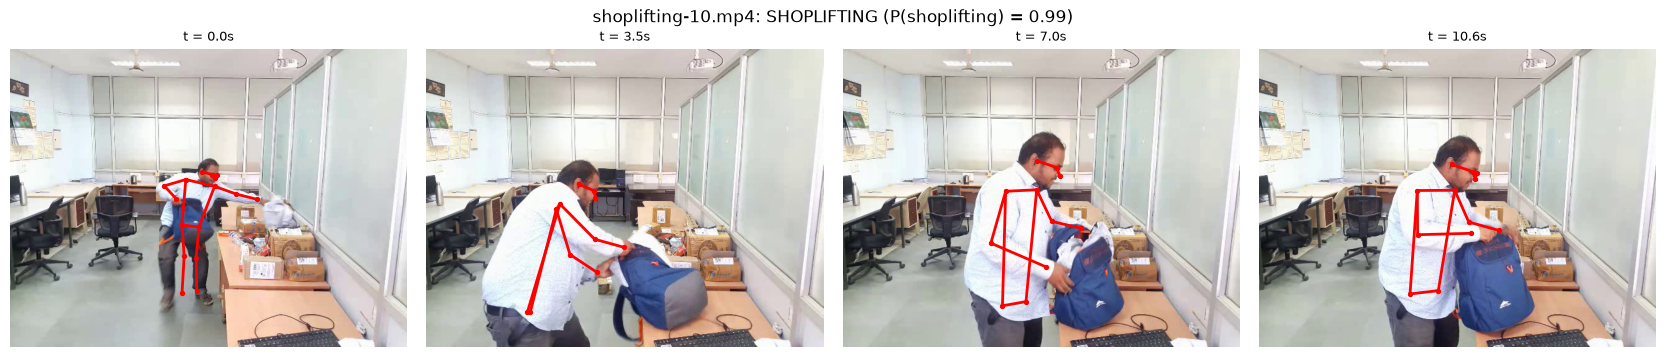

In [3]:
def show_prediction(result, n_frames=4):
    """A few frames with the detected skeletons and the prediction in the title."""
    ext = result["extraction"]
    ts = np.linspace(0, len(ext["kpts"]) - 1, n_frames).astype(int)
    fig, axes = plt.subplots(1, n_frames, figsize=(4.2 * n_frames, 3.6))
    for ax, t in zip(axes, ts):
        pu.draw_pose_frame(ax, result["video"], ext, t)
        ax.set_title(f"t = {t / ext['fps_sampled']:.1f}s", fontsize=9)
    fig.suptitle(f"{Path(result['video']).name}: {result['label'].upper()} (P(shoplifting) = {result['probability']:.2f})")
    plt.tight_layout()
    plt.show()


show_prediction(result)

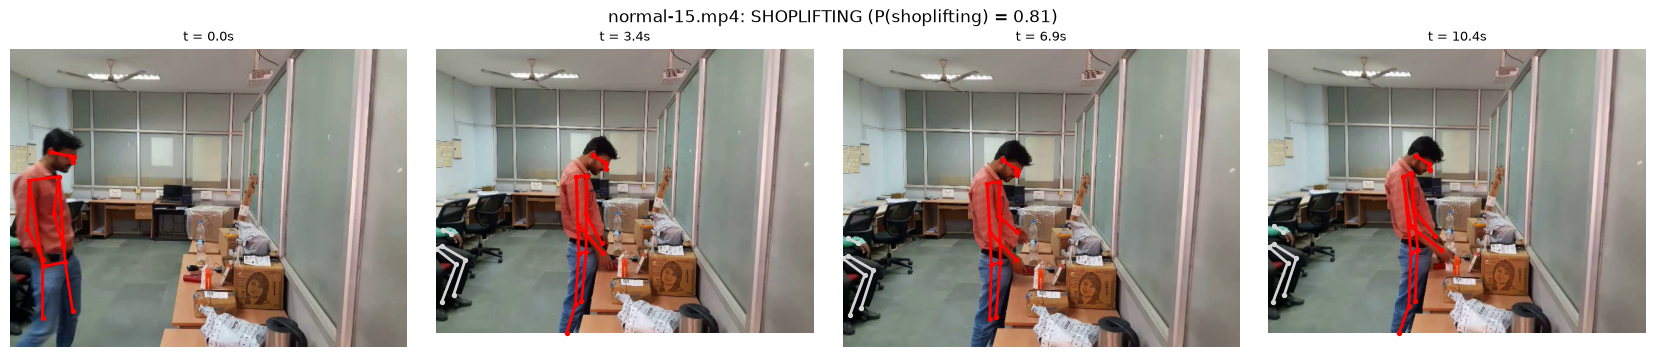

In [4]:
VIDEO2 = test[(test.label_name == "normal") & (test.source == "staged") & person_visible].iloc[0].video_path
result2 = predictor.predict(VIDEO2, keep_extraction=True)
show_prediction(result2)

Both demo clips come from the test set, so we know their true labels. The model is not always right (see the misclassified list in notebook 04):

In [5]:
truth = manifest.set_index("video_path")["label_name"]
for r in (result, result2):
    verdict = "correct" if r["label"] == truth[r["video"]] else "WRONG (a misclassification)"
    print(f"{Path(r['video']).name}: true label {truth[r['video']]}, predicted {r['label']} "
          f"(P(shoplifting) = {r['probability']:.2f}) -> {verdict}")

shoplifting-10.mp4: true label shoplifting, predicted shoplifting (P(shoplifting) = 0.99) -> correct
normal-15.mp4: true label normal, predicted shoplifting (P(shoplifting) = 0.81) -> WRONG (a misclassification)


**Empty scenes.** A few staged "normal" clips show an empty room. Nobody is detected, so the result carries `no_person_detected = True` and should not be trusted as a judgement about behaviour:

In [6]:
EMPTY = test[test["relative_path"].map(quality["primary_rate"]) == 0].iloc[0].video_path
predictor.predict(EMPTY)

{'video': 'C:\\Users\\javier\\Desktop\\IS424 DATA MINING\\Project\\cleaned_unified_deduplicated\\videos\\normal\\normal-13.mp4',
 'label': 'normal',
 'probability': 0.00011514544804560625,
 'approach': 'A',
 'no_person_detected': True}

## 2. A whole folder

`predict_folder` classifies every `.mp4` in a folder. The demo uses the 3 quarantined clips: exact duplicates of normal training clips, removed during cleaning. They only show that the function works; they are **not** a fair accuracy test.

In [7]:
def predict_folder(folder, pattern="*.mp4"):
    rows = [predictor.predict(p) for p in sorted(Path(folder).glob(pattern))]
    return pd.DataFrame(rows, columns=["video", "label", "probability", "approach", "no_person_detected"])


demo_folder = pu.DATA_DIR / "quarantine" / "exact_duplicates" / "videos" / "normal"
predict_folder(demo_folder).assign(video=lambda d: d["video"].map(lambda p: Path(p).name)).round(3)

,video,label,probability,approach,no_person_detected
0,normal-51.mp4,normal,0.000,A,False
1,normal-52.mp4,normal,0.000,A,False
2,normal-56.mp4,normal,0.463,A,False


## 3. One-liner

From any notebook or script in this folder:
```python
import pose_utils as pu
pu.predict_clip("path/to/clip.mp4")   # {'label': 'shoplifting', 'probability': 0.87, ...}
```

In [8]:
pu.predict_clip(VIDEO2)

{'video': 'C:\\Users\\javier\\Desktop\\IS424 DATA MINING\\Project\\cleaned_unified_deduplicated\\videos\\normal\\normal-15.mp4',
 'label': 'shoplifting',
 'probability': 0.8076241508991939,
 'approach': 'A',
 'no_person_detected': False}